# Soft Augmentation: my experiment

Paper: Soft Augmentation for Image Classification (Liu et al., CVPR 2023)

**Problem:** a heavily cropped picture still gets a "100% cat" label.
**Fix:** the more is hidden, the softer the label.

p = 1 - (1 - chance) * (1 - visible) ** 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Research/confused_kitty_lab
!ls

/content/drive/MyDrive/Research/confused_kitty_lab
data  doubt_meter.py.ipynb  soft_augmentation


 ***Experiment***
## My functions

- `my_prob`: how sure the label is
- `my_doubt`: 1 - p
- `my_soft_label`: p for the right class, doubt shared by the others

Checked by hand: 10 classes, 50% visible → p = 0.775

In [ ]:
def my_prob(visible, n_classes):
    chance = 1/n_classes
    p = 1-(1- chance)*(1-visible)**2
    return p

print("probability is ",my_prob(0.5, 10))

# function to find the doubt
def my_doubt(visible, n_classes):
    return 1-my_prob(visible, n_classes)
print("Doubt is", round(my_doubt(0.5, 10), 3))

# function for soft label
def my_soft_label(visible, n_classes):
    p = my_prob(visible, n_classes)
    x = (1-p)/(n_classes-1)
    labels = [p] + [x] * (n_classes-1)#lets we have three pictures: cat,dog,duck
    return labels

print("Soft label:", my_soft_label(0.25, 3))


probability is  0.775
Doubt is 0.225
Soft label: [0.625, 0.1875, 0.1875]


## CIFAR-10

- 60,000 tiny pictures (32 x 32)
- 10 classes, label = number 0 to 9

Plan: slide a picture, count what is visible, find p.
Expect: more lost → lower p (never below 0.1)

In [ ]:
import torchvision
import matplotlib.pyplot as plt
import numpy as np

data = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
print(len(data))
print(data.classes)

50000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


9 truck


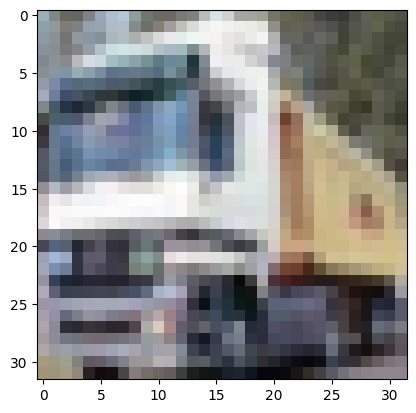

In [ ]:
picture , label = data[1]
print(label, data.classes[label])
plt.imshow(picture, interpolation='nearest')
plt.show()

In [ ]:
!git clone https://github.com/youngleox/soft_augmentation # get the paper's code from github
%cd soft_augmentation/cifar
!ls

fatal: destination path 'soft_augmentation' already exists and is not an empty directory.
/content/drive/MyDrive/Research/confused_kitty_lab/soft_augmentation/cifar
checkpoint  conf  dataset.py	models	     read_me.sh  train.py
cifar.py    data  lr_finder.py	__pycache__  runs	 utils.py


In [ ]:
!nvidia-smi # colab gave the GPU
!cat read_me.sh # read author example from the github

Sat Nov 14 18:13:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!python train.py --task cifar10 --net resnet18 --da 0 --loss ce --sch 0.25 --ft 5 --n 2 --seed 0

Streaming output truncated to the last 5000 lines.
Training Epoch: 38 [14336/50000]	Loss: 0.1044	LR: 0.014570
Training Epoch: 38 [14464/50000]	Loss: 0.0871	LR: 0.014564
Training Epoch: 38 [14592/50000]	Loss: 0.1074	LR: 0.014558
Training Epoch: 38 [14720/50000]	Loss: 0.0468	LR: 0.014553
Training Epoch: 38 [14848/50000]	Loss: 0.0253	LR: 0.014547
Training Epoch: 38 [14976/50000]	Loss: 0.0524	LR: 0.014542
Training Epoch: 38 [15104/50000]	Loss: 0.0885	LR: 0.014536
Training Epoch: 38 [15232/50000]	Loss: 0.0290	LR: 0.014531
Training Epoch: 38 [15360/50000]	Loss: 0.0528	LR: 0.014525
Training Epoch: 38 [15488/50000]	Loss: 0.0559	LR: 0.014520
Training Epoch: 38 [15616/50000]	Loss: 0.0876	LR: 0.014514
Training Epoch: 38 [15744/50000]	Loss: 0.1268	LR: 0.014508
Training Epoch: 38 [15872/50000]	Loss: 0.0535	LR: 0.014503
Training Epoch: 38 [16000/50000]	Loss: 0.0453	LR: 0.014497
Training Epoch: 38 [16128/50000]	Loss: 0.1290	LR: 0.014492
Training Epoch: 38 [16256/50000]	Loss: 0.0387	LR: 0.014486
Train

This line tells Colab to start training a model (ResNet-18) on CIFAR-10 pictures with the normal method, which is our baseline.
It’s only a quick test (a few minutes), just to check the code works before the real, long training

**Soft model**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive
!git clone https://github.com/youngleox/soft_augmentation
%cd soft_augmentation/cifar

In [ ]:
!ls

checkpoint  conf  dataset.py	models	     read_me.sh  train.py
cifar.py    data  lr_finder.py	__pycache__  runs	 utils.py


In [ ]:
!python train.py --task cifar10 --net resnet18 --da 2 --loss st --pcrop 2 --crop 12 --sch 0.25 --ft 5 --n 2 --seed 0

Streaming output truncated to the last 5000 lines.
Training Epoch: 38 [23552/50000]	Loss: 0.1673	LR: 0.014172
Training Epoch: 38 [23680/50000]	Loss: 0.1312	LR: 0.014166
Training Epoch: 38 [23808/50000]	Loss: 0.1017	LR: 0.014161
Training Epoch: 38 [23936/50000]	Loss: 0.1693	LR: 0.014155
Training Epoch: 38 [24064/50000]	Loss: 0.1503	LR: 0.014150
Training Epoch: 38 [24192/50000]	Loss: 0.2002	LR: 0.014144
Training Epoch: 38 [24320/50000]	Loss: 0.1395	LR: 0.014139
Training Epoch: 38 [24448/50000]	Loss: 0.1601	LR: 0.014133
Training Epoch: 38 [24576/50000]	Loss: 0.1642	LR: 0.014128
Training Epoch: 38 [24704/50000]	Loss: 0.1115	LR: 0.014122
Training Epoch: 38 [24832/50000]	Loss: 0.1622	LR: 0.014117
Training Epoch: 38 [24960/50000]	Loss: 0.1651	LR: 0.014111
Training Epoch: 38 [25088/50000]	Loss: 0.1289	LR: 0.014106
Training Epoch: 38 [25216/50000]	Loss: 0.1672	LR: 0.014100
Training Epoch: 38 [25344/50000]	Loss: 0.1531	LR: 0.014095
Training Epoch: 38 [25472/50000]	Loss: 0.1748	LR: 0.014089
Train

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/soft_augmentation/cifar
import torch
print(torch.cuda.is_available())

Mounted at /content/drive
/content/drive/MyDrive/soft_augmentation/cifar
True


In [ ]:
!python train.py --task cifar10 --net resnet18 --da 0 --loss ce --sch 0.25 --ft 5 --n 2 --seed 0

Streaming output truncated to the last 5000 lines.
Training Epoch: 38 [14336/50000]	Loss: 0.1044	LR: 0.014570
Training Epoch: 38 [14464/50000]	Loss: 0.0871	LR: 0.014564
Training Epoch: 38 [14592/50000]	Loss: 0.1074	LR: 0.014558
Training Epoch: 38 [14720/50000]	Loss: 0.0468	LR: 0.014553
Training Epoch: 38 [14848/50000]	Loss: 0.0253	LR: 0.014547
Training Epoch: 38 [14976/50000]	Loss: 0.0524	LR: 0.014542
Training Epoch: 38 [15104/50000]	Loss: 0.0885	LR: 0.014536
Training Epoch: 38 [15232/50000]	Loss: 0.0290	LR: 0.014531
Training Epoch: 38 [15360/50000]	Loss: 0.0528	LR: 0.014525
Training Epoch: 38 [15488/50000]	Loss: 0.0559	LR: 0.014520
Training Epoch: 38 [15616/50000]	Loss: 0.0876	LR: 0.014514
Training Epoch: 38 [15744/50000]	Loss: 0.1268	LR: 0.014508
Training Epoch: 38 [15872/50000]	Loss: 0.0535	LR: 0.014503
Training Epoch: 38 [16000/50000]	Loss: 0.0453	LR: 0.014497
Training Epoch: 38 [16128/50000]	Loss: 0.1290	LR: 0.014492
Training Epoch: 38 [16256/50000]	Loss: 0.0387	LR: 0.014486
Train

In [ ]:
!find /content/drive/MyDrive/soft_augmentation -name "*.pth" | grep DA0

/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA0_MaxP1.0_L0.0_sch0.25__sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_16h_25m_11s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA0_MaxP1.0_L0.0_sch0.25__sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_16h_25m_11s/resnet18-25-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA0_MaxP1.0_L0.0_sch0.25__sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_16h_25m_11s/resnet18-50-regular.pth


In [ ]:
!python train.py --task cifar10 --net resnet18 --da 2 --loss st --pcrop 2 --crop 12 --sch 0.25 --ft 5 --n 2 --seed 0

Streaming output truncated to the last 5000 lines.
Training Epoch: 38 [23552/50000]	Loss: 0.1617	LR: 0.014172
Training Epoch: 38 [23680/50000]	Loss: 0.1129	LR: 0.014166
Training Epoch: 38 [23808/50000]	Loss: 0.1010	LR: 0.014161
Training Epoch: 38 [23936/50000]	Loss: 0.1562	LR: 0.014155
Training Epoch: 38 [24064/50000]	Loss: 0.1609	LR: 0.014150
Training Epoch: 38 [24192/50000]	Loss: 0.2127	LR: 0.014144
Training Epoch: 38 [24320/50000]	Loss: 0.1436	LR: 0.014139
Training Epoch: 38 [24448/50000]	Loss: 0.1624	LR: 0.014133
Training Epoch: 38 [24576/50000]	Loss: 0.1454	LR: 0.014128
Training Epoch: 38 [24704/50000]	Loss: 0.1197	LR: 0.014122
Training Epoch: 38 [24832/50000]	Loss: 0.1603	LR: 0.014117
Training Epoch: 38 [24960/50000]	Loss: 0.1323	LR: 0.014111
Training Epoch: 38 [25088/50000]	Loss: 0.1334	LR: 0.014106
Training Epoch: 38 [25216/50000]	Loss: 0.1624	LR: 0.014100
Training Epoch: 38 [25344/50000]	Loss: 0.1522	LR: 0.014095
Training Epoch: 38 [25472/50000]	Loss: 0.1637	LR: 0.014089
Train

In [ ]:
!find /content/drive/MyDrive/soft_augmentation -name "*.pth" | grep DA2


/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Saturday_14_November_2026_10h_09m_13s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Saturday_14_November_2026_18h_53m_04s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_17h_04m_17s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_17h_04m_17s/resnet18-25-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0

**FGSM ATTACK**

In [ ]:
import torch
import torch.nn.functional as F
def fgsm(model, images, labels, eps):
      model.eval()
      images = images.clone()
      images.requires_grad = True
      loss = F.cross_entropy(model(images), labels)
      loss.backward()
      adv_images = images + eps * torch.sign(images.grad)
      adv_images = torch.clamp(adv_images, 0, 1)
      return adv_images.detach()


In [ ]:
model = torch.nn.Sequential(torch.nn.Flatten(), torch.nn.Linear(3*32*32, 10))
images = torch.rand(8, 3, 32, 32)
labels = torch.randint(0, 10, (8,))

before = F.cross_entropy(model(images), labels).item()
adv = fgsm(model, images, labels, 0.03)
after = F.cross_entropy(model(adv), labels).item()
print(before, after)

2.502525806427002 3.301182746887207


In [ ]:
!grep -rn "Normalize" /content/drive/MyDrive/soft_augmentation/cifar --include=*.py

/content/drive/MyDrive/soft_augmentation/cifar/utils.py:302:    t.extend([transforms.ToTensor(), transforms.Normalize(mean, std)])
/content/drive/MyDrive/soft_augmentation/cifar/utils.py:339:        transforms.Normalize(mean, std)
/content/drive/MyDrive/soft_augmentation/cifar/utils.py:368:        transforms.Normalize(mean, std)


In [ ]:
!sed -n 290,372p /content/drive/MyDrive/soft_augmentation/cifar/utils.py

                            n_class=nclass,
                            sigma_crop=sigma_crop, t_crop=1.0, 
                            max_p_crop=max_p, pow_crop=pow_crop, 
                            bg_crop=bg_crop,
                            iou=iou)
        

    if aa == 1:
        print('using Random Augmentation')
        t.append(transforms.RandAugment())

    
    t.extend([transforms.ToTensor(), transforms.Normalize(mean, std)])

    if da == 1:
        t.append(Cutout(n_holes=1,length=length_cut,mask=mask_cut))
        
    transform_train = transforms.Compose(t)
    if task == 'cifar100':
        cifar100_training = CIFAR100S(root='./data', train=True, download=True, 
                                      transform=transform_train,
                                      custom_transform=custom_transform,
                                      transform_post=t2)#,alpha=alpha)
        print('CIFAR 100 training set')
    elif task == 'cifar10':
        cifar100_training = CIFA

In [ ]:
class Wrapped(torch.nn.Module):
    def __init__(self, model, mean, std):
        super().__init__()
        self.model = model
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):
        return self.model((x - self.mean) / self.std)

In [ ]:
!grep -n "mean\|std\|get_network\|torch.load\|load_state_dict\|torch.save" /content/drive/MyDrive/soft_augmentation/cifar/train.py

31:from utils import get_network, get_training_dataloader, \
56:            loss = ((1-pt)**args.g * ce_loss).mean() # mean over the batch
145:            loss = ((1-pt)**args.g * ce_loss).mean() # mean over the batch   
167:    mean_loss = test_loss / len(dataloader.dataset)
171:        name, mean_loss, acc, finish - start ))
175:        writer.add_scalar('Train/Average loss', mean_loss, epoch)
179:        writer.add_scalar('Test/Average loss', mean_loss, epoch)
183:    return acc, mean_loss
240:                        help='mean cutout length')
299:        mean = settings.CIFAR100_TRAIN_MEAN
300:        std = settings.CIFAR100_TRAIN_STD
304:        mean=[x / 255.0 for x in [125.3, 123.0, 113.9]]
305:        std=[x / 255.0 for x in [63.0, 62.1, 66.7]]
314:    net = get_network(args)
317:        mean,
318:        std,
332:        mean,
333:        std,
341:        mean,
342:        std,
457:                    mean,
458:                    std,
501:            torch.save(net.state_dict

In [ ]:
!grep -n "def get_network" -A 40 /content/drive/MyDrive/soft_augmentation/cifar/utils.py

25:def get_network(args):
26-    """ return given network
27-    """
28-    if args.task == 'cifar10':
29-        nclass = 10
30-    elif args.task == 'cifar100':
31-        nclass = 100
32-
33-    if args.net == 'resnet18':
34-        from models.resnet import resnet18
35-        net = resnet18(num_classes=nclass)
36-    elif args.net == 'resnet50':
37-        from models.resnet import resnet50
38-        net = resnet50(num_classes=nclass)
39-    elif args.net == 'resnet101':
40-        from models.resnet import resnet101
41-        net = resnet101(num_classes=nclass)
42-
43-    # Wide Resnet
44-    elif args.net == 'wideresnet28':
45-        from models.wideresnet import wideresnet28d0
46-        net = wideresnet28d0(num_classes=nclass)
47-
48-    # PyramidNet
49-    elif args.net == 'pyramid272':
50-        from models.pyramidnet import PyramidNet
51-        net = PyramidNet('cifar', depth=272, alpha=200, 
52-                            num_classes=nclass, bottleneck=True)
53-
54-  

In [ ]:
!find /content/drive/MyDrive/soft_augmentation -name "*.pth"

/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Saturday_14_November_2026_10h_09m_13s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Saturday_14_November_2026_18h_53m_04s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_17h_04m_17s/resnet18-0-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_17h_04m_17s/resnet18-25-regular.pth
/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/seed0_DA2st_rw__Crop12.0

In [ ]:
import sys, torch
import torch.nn.functional as F
sys.path.insert(0, '/content/drive/MyDrive/soft_augmentation/cifar')
from models.resnet import resnet18

base = '/content/drive/MyDrive/soft_augmentation/cifar/checkpoint/cifar10/resnet18/'
CKPTS = {
    'baseline (DA0)': base + 'seed0_DA0_MaxP1.0_L0.0_sch0.25__sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_16h_25m_11s/resnet18-50-regular.pth',
    'soft aug (DA2st)': base + 'seed0_DA2st_rw__Crop12.0P2.0BG0.01_sch0.25_DE_c_R_1000.0_sgd0.1NAG_momentum_0.9_wd_0.0005/Monday_16_November_2026_17h_04m_17s/resnet18-50-regular.pth',
}

def load_model(path):
    net = resnet18(num_classes=10)
    ckpt = torch.load(path, map_location=device)
    ckpt = {k.replace('module.', '', 1): v for k, v in ckpt.items()}
    net.load_state_dict(ckpt)
    return Wrapped(net, mean, std).to(device).eval()

def fgsm(model, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    return (x + eps * x.grad.sign()).clamp(0, 1).detach()

for name, path in CKPTS.items():
    model = load_model(path)
    clean = adv = total = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            clean += (model(x).argmax(1) == y).sum().item()
        x_adv = fgsm(model, x, y, EPS)

        with torch.no_grad():
            adv += (model(x_adv).argmax(1) == y).sum().item()
        total += y.size(0)
    print(f'{name:18s} clean: {clean/total:.4f}   FGSM(8/255): {adv/total:.4f}')

baseline (DA0)     clean: 0.9419   FGSM(8/255): 0.2873
soft aug (DA2st)   clean: 0.9477   FGSM(8/255): 0.4769


**FGSM and PGD at all four ε values, both models, one table**

In [ ]:
def pgd(model, x, y, eps, alpha=None, steps=10):
    alpha = alpha or eps / 4
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

def accuracy(model, attack, eps):
    correct = total = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        x_in = x if attack is None else attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x_in).argmax(1) == y).sum().item()
        total += y.size(0)
    return correct / total

EPS_LIST = [1/255, 2/255, 4/255, 8/255]
results = {}
for name, path in CKPTS.items():
    model = load_model(path)
    results[name] = {'clean': accuracy(model, None, 0)}
    for e in EPS_LIST:
        k = round(e * 255)
        results[name][f'FGSM {k}/255'] = accuracy(model, fgsm, e)
        results[name][f'PGD {k}/255']  = accuracy(model, pgd, e)

import pandas as pd

df = pd.DataFrame(results).T
print((df * 100).round(2).to_string())

                  clean  FGSM 1/255  PGD 1/255  FGSM 2/255  PGD 2/255  FGSM 4/255  PGD 4/255  FGSM 8/255  PGD 8/255
baseline (DA0)    94.19       61.19      40.71       45.29      11.19       34.94       1.69       28.73       0.05
soft aug (DA2st)  94.77       64.56      44.17       57.24      27.76       52.61      15.90       47.69       7.44
